# Add a method and preserve a fair comparison

This notebook takes an estimator from the public `CATEMethod` interface through a reproducible benchmark run. You will inspect paired CATE scores, resume a completed run, and see how malformed predictions and missing results affect coverage.

Use Python 3.11+ with this package's **baselines and notebook dependencies already installed**, then **Restart Kernel and Run All**. The cells make no downloads, use no repository-relative input files, and write only into a temporary directory. The fixed run has 18 successful cells plus a separate two-cell failure demonstration. Use appropriately provisioned compute for larger studies.

The examples are development checks. Three seeds cannot establish a method ranking. The estimator, settings and seeds below are declared before any score is inspected.


In [1]:
%matplotlib inline
from dataclasses import fields, replace
import importlib.metadata
import json
from pathlib import Path
import tempfile

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from obs_rct_benchmark.data import TrainingView
from obs_rct_benchmark.evaluation import summarize_records
from obs_rct_benchmark.methods import custom_provenance, register_method
from obs_rct_benchmark.runner import BenchmarkConfig, ScenarioConfig, run_benchmark

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})


def show_table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |",
             "| " + " | ".join(["---"] * len(headers)) + " |"]
    lines.extend("| " + " | ".join(map(str, row)) + " |" for row in rows)
    display(Markdown("\n".join(lines)))


print("obs-rct-benchmark:", importlib.metadata.version("obs-rct-benchmark"))
print("NumPy:", np.__version__)


obs-rct-benchmark: 0.1.0a1
NumPy: 1.26.4


## The information supplied to a method

`fit_predict(training, eval_X, *, seed)` must return a finite, one-dimensional array with exactly one CATE prediction per query row.

| Input | Permitted use |
| --- | --- |
| `training.obs_train` | Observed OBS covariates, treatment and outcome |
| `training.rct_train` | Observed RCT data and supplied randomization probabilities |
| `training.rct_tune` | Disclosed observed-data tuning; unused in this example |
| `training.target_reference` | Optional, separate outcome-free target covariates; absent here |
| `eval_X` | Prediction queries only; do not fit preprocessing or adaptation on these rows |
| `seed` | Method RNG stream; seed every stochastic component you control |

The runner retains effect truth, hidden variables and `rct_test`. The interface is an information contract, not a sandbox for untrusted code. Do not reach into evaluator files or close over a simulation object. See the [evaluation protocol](../docs/PROTOCOL.md).


In [2]:
observed_fields = tuple(field.name for field in fields(TrainingView))
print("TrainingView fields:", observed_fields)
assert "eval_tau" not in observed_fields
assert "truth" not in observed_fields
assert "rct_test" not in observed_fields


TrainingView fields: ('obs_train', 'rct_train', 'rct_tune', 'target_reference')


## A transparent reference estimator

We implement a constant RCT Horvitz–Thompson effect:

\[
\widehat\theta = \frac{1}{n}\sum_i\left[\frac{T_iY_i}{e_i}
                         - \frac{(1-T_i)Y_i}{1-e_i}\right].
\]

The supplied `e_i` is the RCT randomization probability. Conditional on a trial participant's potential outcomes, randomization makes the expectation of each bracket equal to `Y_i(1) - Y_i(0)`. We broadcast the estimate to every query row.

This is a deliberately simple reference, not a heterogeneous-effect learner. It targets the trial's average effect under randomization; transporting that average to another population needs additional assumptions. It cannot represent variation of CATE across covariates. It uses only `rct_train`, has no hyperparameters, and is deterministic, so its method seed is unused. The two ridge baselines also use fixed defaults.


In [3]:
class RCTConstantHT:
    """Constant RCT effect using the supplied, possibly varying propensities."""

    def fit_predict(self, training: TrainingView, eval_X: np.ndarray, *,
                    seed: int) -> np.ndarray:
        if not isinstance(training, TrainingView):
            raise TypeError("a TrainingView is required")
        sample = training.rct_train
        probability = sample.known_propensity
        if probability is None or not np.all((probability > 0) & (probability < 1)):
            raise ValueError("valid known RCT randomization probabilities are required")
        pseudo_outcome = (sample.T * sample.Y / probability
                          - (1 - sample.T) * sample.Y / (1 - probability))
        effect = float(np.mean(pseudo_outcome))
        if not np.isfinite(effect):
            raise ValueError("the estimated effect is not finite")
        return np.full(eval_X.shape[0], effect, dtype=np.float64)


In [4]:
CUSTOM = "tutorial_rct_constant_ht_v1"
PROVENANCE = "public-notebook:04_custom_method_and_reproducibility:RCTConstantHT:v1"
register_method(CUSTOM, RCTConstantHT, provenance=PROVENANCE)
print({CUSTOM: custom_provenance()[CUSTOM]})


{'tutorial_rct_constant_ht_v1': 'public-notebook:04_custom_method_and_reproducibility:RCTConstantHT:v1'}


## Declare the run before scoring

The two structural presets are M0 and M1. M0 removes hidden treatment selection; M1 uses global arm-specific bias. They also differ in CATE geometry, so their difference is **not an isolated confounding contrast**. Consult [coverage](../docs/COVERAGE.md) when choosing a scientific comparison.

Each scenario/seed gets 120 OBS, 60 RCT training, 30 tuning, 30 reserved test and 128 evaluation rows. All methods receive the same realized training and evaluation data within that scenario/seed. The three simulation seeds index replicate datasets. The runner derives a separate, stable method seed for each scenario/seed/method; changing a method's name changes its method RNG stream.


In [5]:
BUDGETS = dict(n_obs=120, n_rct_train=60, n_rct_tune=30,
               n_rct_test=30, n_eval=128)
SEEDS = (17, 29, 43)
config = BenchmarkConfig(
    scenarios=tuple(ScenarioConfig("structural", name, dict(BUDGETS))
                    for name in ("M0", "M1")),
    seeds=SEEDS,
    methods=("rct_t_ridge", "obs_t_ridge", CUSTOM),
    reference_method="rct_t_ridge",
    scope="tutorial/development-inspected; fixed three-seed grid; no ranking claim",
)
workspace = tempfile.TemporaryDirectory(prefix="obsrct-notebook-")
output = Path(workspace.name) / "comparison"
print("Requested cells:", len(config.scenarios) * len(SEEDS) * len(config.methods))
print("Config hash:", config.config_hash)


Requested cells: 18
Config hash: e86407c32a0cdeb4ce6b6b9e0ebacae7971ff2249448a6396a55a6aa5525a916


In [6]:
summary = run_benchmark(config, output)
records_path = output / "records.jsonl"
records = [json.loads(line) for line in records_path.read_text().splitlines()]
manifest = json.loads((output / "run_manifest.json").read_text())
assert summary["status"] == "complete", summary["coverage"]
assert len(records) == 18
show_table(["status", "expected", "successful", "failed", "missing"],
           [[summary["status"], *(summary["coverage"][key] for key in
                                  ("expected", "successful", "failed", "missing"))]])
show_table(["scenario", "data seed", "method", "method seed"],
           [[row[key] for key in ("scenario", "seed", "method", "method_seed")]
            for row in records[:3]])


| status | expected | successful | failed | missing |
| --- | --- | --- | --- | --- |
| complete | 18 | 18 | 0 | 0 |

| scenario | data seed | method | method seed |
| --- | --- | --- | --- |
| structural:M0 | 17 | rct_t_ridge | 4010514895 |
| structural:M0 | 17 | obs_t_ridge | 4015145710 |
| structural:M0 | 17 | tutorial_rct_constant_ht_v1 | 4182541740 |

## Read the right metric

CATE MSE is `mean((predicted_cate - target_cate)**2)` over evaluation rows. It is **not factual-outcome MSE**. Root-PEHE is the square root of each replicate's CATE MSE. Mean root-PEHE and the square root of mean CATE MSE generally differ.

Below, each dot is one replicate's CATE MSE; bars show the three-replicate mean. The evaluator computes these scores after prediction. No effect truth enters our estimator or chooses its settings.


| scenario | method | mean CATE MSE | mean root-PEHE | coverage |
| --- | --- | --- | --- | --- |
| structural:M0 | rct_t_ridge | 0.8492 | 0.8792 | 3/3 |
| structural:M0 | obs_t_ridge | 0.4062 | 0.6105 | 3/3 |
| structural:M0 | tutorial_rct_constant_ht_v1 | 0.3936 | 0.5734 | 3/3 |
| structural:M1 | rct_t_ridge | 0.9441 | 0.9074 | 3/3 |
| structural:M1 | obs_t_ridge | 0.9399 | 0.9412 | 3/3 |
| structural:M1 | tutorial_rct_constant_ht_v1 | 0.5124 | 0.6715 | 3/3 |

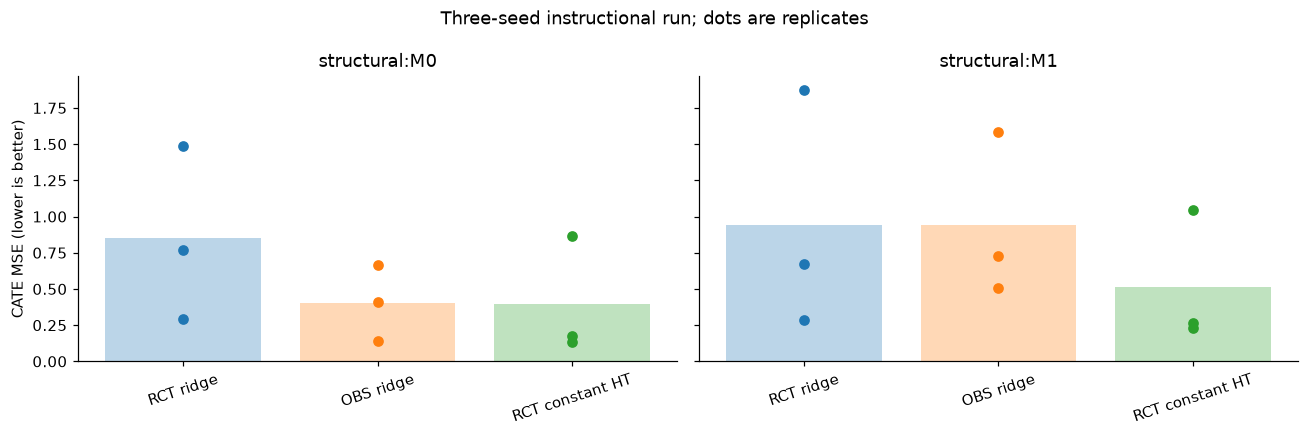

In [7]:
scenario_keys = tuple(scenario.key for scenario in config.scenarios)
show_table(["scenario", "method", "mean CATE MSE", "mean root-PEHE", "coverage"],
           [[scenario, method, f"{value['mean_cate_mse']:.4f}",
             f"{value['mean_root_pehe']:.4f}",
             f"{value['successful']}/{value['expected']}"]
            for scenario in scenario_keys
            for method, value in summary["scenarios"][scenario].items()])

fig, axes = plt.subplots(1, len(scenario_keys), figsize=(12, 4), sharey=True)
for axis, scenario in zip(np.atleast_1d(axes), scenario_keys):
    for index, method in enumerate(config.methods):
        values = [row["metrics"]["cate_mse"] for row in records
                  if row["scenario"] == scenario and row["method"] == method]
        axis.bar(index, np.mean(values), color=f"C{index}", alpha=0.3)
        axis.scatter(np.full(len(values), index), values, color=f"C{index}", zorder=3)
    axis.set(title=scenario, xticks=range(len(config.methods)),
             xticklabels=["RCT ridge", "OBS ridge", "RCT constant HT"])
    axis.tick_params(axis="x", labelrotation=18)
axes[0].set_ylabel("CATE MSE (lower is better)")
fig.suptitle("Three-seed instructional run; dots are replicates")
fig.tight_layout()
plt.show()


## Pair within data seed, then summarize seed blocks

A comparison is `method MSE - reference MSE`, so a negative value favors the method on this fixed grid. First subtract scores on the same realized scenario/seed. For an overall comparison, average the two scenario differences **within each seed**, then summarize those three blocks. Do not count the six scenario/seed pairs, 18 method cells or 128 evaluation rows as independent uncertainty blocks.

The runner also reports a Student t interval over seed blocks. With only three blocks, this is a demonstration of the calculation, not reliable evidence for a general ranking. Scenarios are a fixed chosen set, not a random sample of all possible DGPs.


| method minus RCT ridge | scope | mean MSE difference | seed blocks |
| --- | --- | --- | --- |
| obs_t_ridge | structural:M0 | -0.4430 | 3 |
| obs_t_ridge | structural:M1 | -0.0042 | 3 |
| obs_t_ridge | scenario mean within seed | -0.2236 | 3 |
| tutorial_rct_constant_ht_v1 | structural:M0 | -0.4556 | 3 |
| tutorial_rct_constant_ht_v1 | structural:M1 | -0.4317 | 3 |
| tutorial_rct_constant_ht_v1 | scenario mean within seed | -0.4436 | 3 |

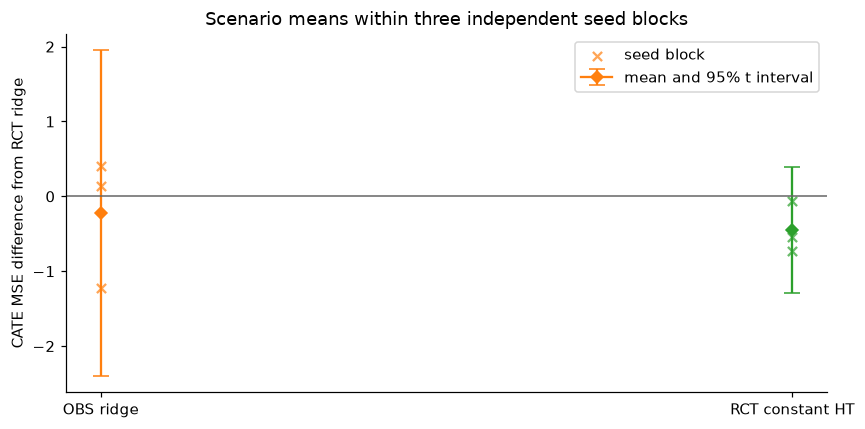

In [8]:
score = {(row["scenario"], row["seed"], row["method"]): row["metrics"]["cate_mse"]
         for row in records}
comparison_methods = tuple(method for method in config.methods
                           if method != config.reference_method)
paired_blocks = {}
table_rows = []
for method in comparison_methods:
    paired_blocks[method] = np.array([
        np.mean([score[scenario, seed, method]
                 - score[scenario, seed, config.reference_method]
                 for scenario in scenario_keys]) for seed in SEEDS
    ])
    paired = summary["paired_comparisons"][method]
    overall = paired["overall"]["metrics"]["cate_mse"]
    assert overall["n_seed_blocks"] == len(SEEDS)
    np.testing.assert_allclose(paired_blocks[method].mean(), overall["mean"])
    for scenario in scenario_keys:
        value = paired["by_scenario"][scenario]["metrics"]["cate_mse"]
        table_rows.append([method, scenario, f"{value['mean']:.4f}",
                           value["n_seed_blocks"]])
    table_rows.append([method, "scenario mean within seed", f"{overall['mean']:.4f}",
                       overall["n_seed_blocks"]])
show_table(["method minus RCT ridge", "scope", "mean MSE difference", "seed blocks"],
           table_rows)

fig, axis = plt.subplots(figsize=(8, 4))
for index, method in enumerate(comparison_methods):
    value = summary["paired_comparisons"][method]["overall"]["metrics"]["cate_mse"]
    lower, upper = value["ci95"]
    axis.errorbar(index, value["mean"],
                  yerr=np.array([[value["mean"] - lower], [upper - value["mean"]]]),
                  color=f"C{index + 1}", marker="D", capsize=5, label="mean and 95% t interval"
                  if index == 0 else None)
    axis.scatter(np.full(len(SEEDS), index), paired_blocks[method],
                 color=f"C{index + 1}", alpha=0.7, marker="x", label="seed block"
                 if index == 0 else None)
axis.axhline(0, color="0.4", linewidth=1)
axis.set(xticks=range(len(comparison_methods)),
         xticklabels=["OBS ridge", "RCT constant HT"],
         ylabel="CATE MSE difference from RCT ridge",
         title="Scenario means within three independent seed blocks")
axis.legend()
fig.tight_layout()
plt.show()


## Check the saved identity and resume

`run_manifest.json` records the declared configuration, resolved DGP controls, installed package source hashes, environment versions and requested custom-method provenance. `records.jsonl` stores individual outcomes; `summary.json` and `README.md` summarize them. Training arrays and effect-truth arrays are not saved by this runner.

The custom-method version string is an **author declaration**: it does not hash or verify this notebook's class automatically. Change it whenever the method changes, and preserve the exact notebook or external source revision with a scientific run. Resume requires the same configuration and recorded source/environment identity. A completed run should leave the record bytes unchanged; resume is not a fresh replication.


In [9]:
print(json.dumps({key: manifest[key] for key in
                  ("config_hash", "custom_methods", "custom_provenance_policy")}, indent=2))
records_before = records_path.read_bytes()
resumed = run_benchmark(config, output, resume=True)
assert resumed["status"] == "complete"
assert records_path.read_bytes() == records_before
print("Completed-run resume preserved all record bytes.")


{
  "config_hash": "e86407c32a0cdeb4ce6b6b9e0ebacae7971ff2249448a6396a55a6aa5525a916",
  "custom_methods": {
    "tutorial_rct_constant_ht_v1": "public-notebook:04_custom_method_and_reproducibility:RCTConstantHT:v1"
  },
  "custom_provenance_policy": "author-supplied identifiers; custom source is not automatically verified"
}
Completed-run resume preserved all record bytes.


In [10]:
changed = replace(config, seeds=SEEDS + (59,))
try:
    run_benchmark(changed, output, resume=True)
except ValueError:
    print("Expected rejection: the resumed configuration differs from the manifest.")
else:
    raise AssertionError("a changed configuration must not resume the old run")
assert records_path.read_bytes() == records_before


Expected rejection: the resumed configuration differs from the manifest.


## Make failures and missing cells visible

The following adapter deliberately returns a two-dimensional column array. The metric contract rejects it: its record must be `failed` with no numeric score. Failed records are terminal on resume, so retrying cannot silently remove a poor or invalid result.

A separate, in-memory example omits one successful record to illustrate an interrupted run. Failed and missing cells are both counted. Comparisons that lack the full requested coverage are withheld, rather than reporting a mean over whichever seeds happened to succeed. Fix an invalid implementation, change its provenance, and start a disclosed new run.


In [11]:
class InvalidColumnPrediction:
    def fit_predict(self, training, eval_X, *, seed):
        return np.zeros((eval_X.shape[0], 1))  # Deliberate contract violation.


BROKEN = "tutorial_invalid_column_v1"
register_method(BROKEN, InvalidColumnPrediction,
                provenance="public-notebook:deliberate-invalid-column:v1")
failure_config = replace(config, scenarios=(config.scenarios[0],), seeds=(SEEDS[0],),
                         methods=(config.reference_method, BROKEN))
failure_output = Path(workspace.name) / "deliberate-failure"
failure_summary = run_benchmark(failure_config, failure_output)
failure_records_path = failure_output / "records.jsonl"
failure_records = [json.loads(line) for line in failure_records_path.read_text().splitlines()]
invalid = next(row for row in failure_records if row["method"] == BROKEN)
assert invalid["status"] == "failed" and invalid["metrics"] is None
assert failure_summary["status"] == "incomplete"
assert not failure_summary["paired_comparisons"][BROKEN]["overall"]["eligible_for_comparison"]
failure_bytes = failure_records_path.read_bytes()
run_benchmark(failure_config, failure_output, resume=True)
assert failure_records_path.read_bytes() == failure_bytes
print({key: invalid[key] for key in ("method", "status", "stage", "error_type", "metrics")})
print("Failed-record resume preserved all record bytes.")


{'method': 'tutorial_invalid_column_v1', 'status': 'failed', 'stage': 'method_or_metric', 'error_type': 'ValueError', 'metrics': None}
Failed-record resume preserved all record bytes.


In [12]:
# This changes no saved run: it only illustrates the public summary API.
missing_records = records[:-1]
missing_summary = summarize_records(
    missing_records, scenarios=scenario_keys, seeds=SEEDS,
    methods=config.methods, reference_method=config.reference_method,
)
missing_method = records[-1]["method"]
assert missing_summary["coverage"]["missing"] == 1
assert not missing_summary["paired_comparisons"][missing_method]["overall"]["eligible_for_comparison"]
show_table(["illustration", "successful", "failed", "missing", "comparison eligible"], [
    ["invalid prediction", failure_summary["coverage"]["successful"],
     failure_summary["coverage"]["failed"], failure_summary["coverage"]["missing"],
     failure_summary["paired_comparisons"][BROKEN]["overall"]["eligible_for_comparison"]],
    ["one record missing", missing_summary["coverage"]["successful"],
     missing_summary["coverage"]["failed"], missing_summary["coverage"]["missing"],
     missing_summary["paired_comparisons"][missing_method]["overall"]["eligible_for_comparison"]],
])


| illustration | successful | failed | missing | comparison eligible |
| --- | --- | --- | --- | --- |
| invalid prediction | 1 | 1 | 0 | False |
| one record missing | 17 | 0 | 1 | False |

## Turn the exercise into a contribution

Replace the reference class with an adapter to your estimator, while retaining the observed-data boundary and prediction checks. Declare every fitted or tuned sample role, fixed option or observed-data tuning rule, source revision, dependency and RNG rule. Keep unpublished implementations in a separate repository if needed; in-process registration does not require publishing that repository.

Before a scientific comparison, state the hypothesis and target population, select appropriate DGPs and independent replicate budgets, and freeze the evaluation protocol before looking at effect-truth scores. Report complete coverage, failures and paired seed-block uncertainty. Do not tune on this notebook's evaluation scores and then present the same grid as an unseen evaluation.

See the [extension guide](../docs/EXTENDING.md), [evaluation protocol](../docs/PROTOCOL.md) and [contribution guide](../CONTRIBUTING.md). The final cell removes this tutorial's temporary artifacts. For a real study, use a dedicated persistent output directory and preserve the configuration, exact custom source version and manifest.


In [13]:
workspace.cleanup()
print("Temporary tutorial outputs removed. No dataset or benchmark output was added to the repository.")


Temporary tutorial outputs removed. No dataset or benchmark output was added to the repository.
